# Olist Data Analysis

## Setup

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display

from pathlib import Path

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "00_common.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook inside the Olist project folder.")
common_notebook = str(ROOT / "notebooks" / "00_common.ipynb")
%run "$common_notebook"

## Data Loading

In [2]:
run_phase(paths, 'load')
print('Loaded:', paths.db_path)

[load] 00_staging


Loaded: /Users/jeonjaeyeon/ChatGPT/Olist/database/olist.duckdb


## Data Validation

In [3]:
controls = query('SELECT * FROM staging.source_control_totals')
display(controls)
assert (controls.expected_row_count == controls.actual_row_count).all()
display(query('SELECT COUNT(*) AS rows, COUNT(DISTINCT order_id) AS unique_orders, COUNT(*) FILTER (WHERE order_id IS NULL) AS missing_order_ids FROM staging.stg_orders'))
assert query('SELECT COUNT(*) = COUNT(DISTINCT order_id) AS valid FROM staging.stg_orders').iloc[0, 0]

,table_name,expected_row_count,actual_row_count
0,stg_customers,99441,99441
1,stg_geolocation,1000163,1000163
2,stg_order_items,112650,112650
3,stg_order_payments,103886,103886
4,stg_order_reviews,99224,99224
5,stg_orders,99441,99441
6,stg_products,32951,32951
7,stg_sellers,3095,3095
8,stg_category_translation,71,71


,rows,unique_orders,missing_order_ids
0,99441,99441,0


## Preprocessing

In [4]:
run_phase(paths, 'build')

[build] 10_intermediate


[build] 20_marts


In [5]:
run_phase(paths, 'validate')
check_data(paths)
display(query('SELECT * FROM checks.required_checks ORDER BY check_id'))

[validate] 30_data_checks


,check_id,check_name,table_name,rows_tested,affected_count,expected_result
0,B001,Source row counts match the dataset,staging.source_control_totals,9,0,0 mismatched tables
1,B002,Order mart has one row per source order,marts.mart_order_fulfillment,99441,0,99441 rows and unique order_id
2,B003,Order-seller mart grain is unique,marts.mart_order_seller,100010,0,0 duplicate order_id × seller_id rows
3,B004,Order-seller mart reconciles to source pairs,marts.mart_order_seller,100010,0,Matches distinct source order_id × seller_id p...
4,B005,Order-category mart grain is unique,marts.mart_order_category,99470,0,0 duplicate order_id × category rows
5,B006,Gross item value reconciles,intermediate.int_order_items,1,0,Absolute difference <= 0.01
6,B007,Freight value reconciles,intermediate.int_order_items,1,0,Absolute difference <= 0.01
7,B008,Payment total reconciles,intermediate.int_order_payments,1,0,Absolute difference <= 0.01
8,B009,KPI numerators do not exceed denominators,marts.mart_monthly_fulfillment_kpi,20,0,0 invalid monthly rows
9,B010,Monthly KPI denominators are nonzero,marts.mart_monthly_fulfillment_kpi,20,0,0 monthly rows with zero denominators


In [6]:
run_phase(paths, 'analyze')

[analyze] 40_analysis


## Export Aggregates

In [7]:
TABLEAU_EXPORTS = {
    "mart_monthly_fulfillment_kpi": (
        "marts.mart_monthly_fulfillment_kpi",
        "purchase_month",
    ),
    "mart_seller_monthly_sla": (
        "marts.mart_seller_monthly_sla",
        "purchase_month, seller_id",
    ),
    "agg_state_lane_performance": (
        "analysis.agg_state_lane_performance",
        "eligible_delivery_order_count DESC, seller_state, customer_state",
    ),
    "agg_customer_state_performance": (
        "analysis.agg_customer_state_performance",
        "late_delivery_order_count DESC, customer_state",
    ),
    "agg_seller_state_performance": (
        "analysis.agg_seller_state_performance",
        "handover_breach_count DESC, seller_state",
    ),
    "agg_category_performance": (
        "analysis.agg_category_performance",
        "late_delivery_order_count DESC, category_name",
    ),
    "category_fulfillment_stage_performance": (
        "analysis.category_fulfillment_stage_performance",
        "category_name, CASE stage_name WHEN 'Purchase to approval' THEN 1 WHEN 'Approval to carrier handover' THEN 2 WHEN 'Carrier handover to customer delivery' THEN 3 ELSE 4 END",
    ),
    "mart_seller_investigation_queue": (
        "analysis.mart_seller_investigation_queue",
        "priority_sort, handover_breach_count DESC, handover_breach_rate DESC, seller_id",
    ),
    "handover_population_sensitivity": (
        "analysis.handover_population_sensitivity",
        "population_name",
    ),
    "fulfillment_stage_summary": (
        "analysis.fulfillment_stage_summary",
        "CASE stage_name WHEN 'Purchase to approval' THEN 1 WHEN 'Approval to carrier handover' THEN 2 WHEN 'Carrier handover to customer delivery' THEN 3 ELSE 4 END",
    ),
    "handover_delivery_failure_modes": (
        "analysis.handover_delivery_failure_modes",
        "order_count DESC, failure_mode",
    ),
    "fulfillment_stage_by_delivery_outcome": (
        "analysis.fulfillment_stage_by_delivery_outcome",
        "delivery_outcome, stage_name",
    ),
    "fulfillment_stage_share": (
        "analysis.fulfillment_stage_share",
        "stage_name",
    ),
    "delivery_review_association": (
        "analysis.delivery_review_association",
        "CASE delivery_group WHEN 'On time' THEN 1 WHEN 'Late 1-3 days' THEN 2 WHEN 'Late 4-7 days' THEN 3 ELSE 4 END",
    ),
    "mart_seller_region_investigation_queue": (
        "analysis.mart_seller_region_investigation_queue",
        "seller_priority_sort, seller_id, segment_rank_within_seller",
    ),
}

In [8]:
export_tableau(paths, TABLEAU_EXPORTS)

[export] mart_monthly_fulfillment_kpi.csv
[export] mart_seller_monthly_sla.csv
[export] agg_state_lane_performance.csv
[export] agg_customer_state_performance.csv
[export] agg_seller_state_performance.csv
[export] agg_category_performance.csv
[export] category_fulfillment_stage_performance.csv
[export] mart_seller_investigation_queue.csv
[export] handover_population_sensitivity.csv
[export] fulfillment_stage_summary.csv
[export] handover_delivery_failure_modes.csv
[export] fulfillment_stage_by_delivery_outcome.csv
[export] fulfillment_stage_share.csv
[export] delivery_review_association.csv


[export] mart_seller_region_investigation_queue.csv


## Sales Analysis

,month,order_count,gross_item_value
0,2017-01-01,800,120312.87
1,2017-02-01,1780,247303.02
2,2017-03-01,2682,374344.30
3,2017-04-01,2404,359927.23
4,2017-05-01,3700,506071.14
5,2017-06-01,3245,433038.60
6,2017-07-01,4026,498031.48
7,2017-08-01,4331,573971.68
8,2017-09-01,4285,624401.69
9,2017-10-01,4631,664219.43


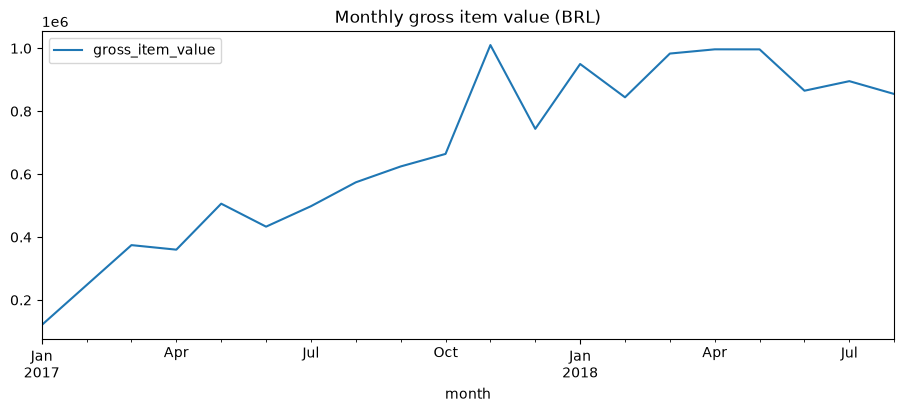

In [9]:
sales = query('''SELECT date_trunc('month', order_purchase_timestamp)::DATE AS month,
COUNT(*) AS order_count, SUM(gross_item_value) AS gross_item_value
FROM marts.mart_order_fulfillment WHERE is_primary_analysis_period
GROUP BY 1 ORDER BY 1''')
display(sales)
sales.plot(x='month', y='gross_item_value', figsize=(11,4), title='Monthly gross item value (BRL)')
plt.show()

## Customer Analysis

In [10]:
customers = query('''WITH customer_orders AS (
SELECT c.customer_unique_id, COUNT(*) AS delivered_orders
FROM marts.mart_order_fulfillment m JOIN staging.stg_customers c USING (customer_id)
WHERE m.is_primary_analysis_period AND m.order_status = 'delivered'
GROUP BY 1)
SELECT COUNT(*) AS customers, COUNT(*) FILTER (WHERE delivered_orders > 1) AS repeat_customers,
AVG((delivered_orders > 1)::INTEGER) AS repeat_customer_rate FROM customer_orders''')
display(customers)
display(query('SELECT * FROM analysis.agg_customer_state_performance ORDER BY late_delivery_order_count DESC'))

,customers,repeat_customers,repeat_customer_rate
0,93104,2789,0.029956


,customer_state,total_order_count,delivery_eligible_order_count,late_delivery_order_count,late_delivery_rate,reviewed_order_count,average_review_score
0,SP,41621,40399,1817,0.044976,41348,4.175534
1,RJ,12792,12310,1495,0.121446,12629,3.881463
2,MG,11591,11319,519,0.045852,11511,4.138650
3,BA,3376,3253,396,0.121734,3336,3.862110
4,RS,5441,5327,325,0.061010,5418,4.135659
5,SC,3625,3537,291,0.082273,3597,4.077009
6,ES,2029,1992,214,0.107430,2002,4.038961
7,PR,5025,4903,199,0.040587,4999,4.182236
8,CE,1328,1273,176,0.138256,1319,3.854435
9,PE,1645,1587,153,0.096408,1628,4.006757


## Delivery Analysis

,purchase_month,total_order_count,delivered_order_count,canceled_order_count,unavailable_order_count,delivery_sla_eligible_count,on_time_delivery_count,end_to_end_eligible_count,end_to_end_p50_hours,end_to_end_p90_hours,...,cancellation_rate,unavailable_rate,on_time_delivery_rate,review_response_coverage,handover_candidate_count,handover_sla_eligible_count,handover_sla_excluded_count,handover_breach_count,handover_breach_rate,handover_observation_coverage
0,2017-01-01,800,750,3,10,750,728,750,257.607500,462.160944,...,0.003750,0.012500,0.970667,0.987500,783,762,21,170,0.223097,0.973180
1,2017-02-01,1780,1653,17,45,1653,1604,1653,263.308889,529.775167,...,0.009551,0.025281,0.970357,0.993258,1706,1662,44,294,0.176895,0.974209
2,2017-03-01,2682,2546,33,32,2546,2430,2546,243.035694,507.373194,...,0.012304,0.011931,0.954438,0.992170,2612,2586,26,173,0.066899,0.990046
3,2017-04-01,2404,2303,18,9,2303,2152,2303,305.966944,607.776111,...,0.007488,0.003744,0.934433,0.992928,2359,2334,25,167,0.071551,0.989402
4,2017-05-01,3700,3546,29,31,3545,3439,3545,235.040000,461.726778,...,0.007838,0.008378,0.970099,0.990811,3608,3568,40,260,0.072870,0.988914
5,2017-06-01,3245,3135,16,24,3135,3040,3135,259.317778,475.789889,...,0.004931,0.007396,0.969697,0.991680,3180,3157,23,245,0.077605,0.992767
6,2017-07-01,4026,3872,28,52,3872,3764,3872,243.793750,474.087333,...,0.006955,0.012916,0.972107,0.991058,3882,3864,18,298,0.077122,0.995363
7,2017-08-01,4331,4193,27,32,4193,4071,4193,234.475556,461.344389,...,0.006234,0.007389,0.970904,0.992381,4214,4176,38,287,0.068726,0.990982
8,2017-09-01,4285,4150,20,38,4150,3968,4150,247.546389,487.905333,...,0.004667,0.008868,0.956145,0.992065,4183,4143,40,300,0.072411,0.990437
9,2017-10-01,4631,4478,26,58,4478,4291,4478,246.320694,482.068639,...,0.005614,0.012524,0.958240,0.991794,4483,4447,36,353,0.079379,0.991970


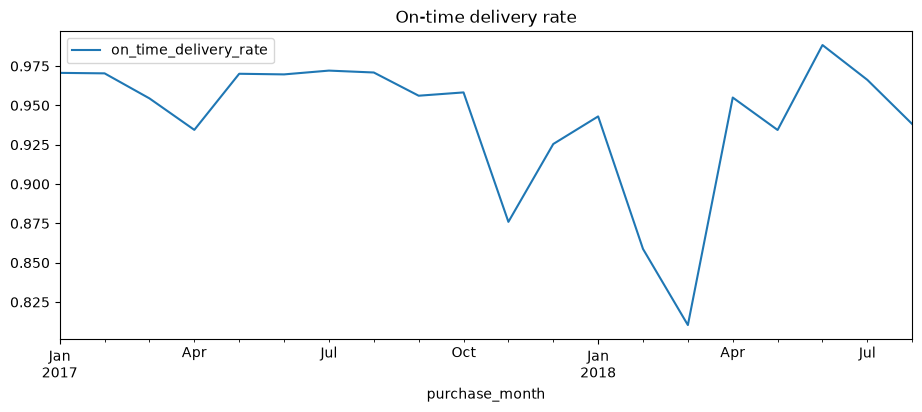

,stage_name,eligible_order_count,excluded_order_count,p50_hours,p75_hours,p90_hours
0,Purchase to approval,98957,135,0.341944,14.485278,34.596444
1,Approval to carrier handover,96003,3089,44.279722,86.358056,143.889833
2,Carrier handover to customer delivery,96184,2908,170.505417,288.859097,453.870750
3,Purchase to customer delivery,96204,2888,245.041667,376.386111,553.552194


,seller_id,seller_state,priority_tier,priority_sort,eligible_order_count,eligible_active_month_count,handover_breach_count,handover_breach_rate,platform_handover_breach_rate,breach_contribution_share,...,breach_delay_p50_hours,breach_delay_p90_hours,platform_breach_delay_p90_hours,delivery_eligible_order_count,late_delivery_order_count,contextual_late_delivery_rate,reviewed_order_count,low_review_order_count,contextual_low_review_rate,reason_codes
0,cd68562d3f44870c08922d380acae552,SP,P1,1,122,12,18,0.147541,0.090095,0.002080,...,24.590278,278.343361,180.689889,122,19,0.155738,121,20,0.165289,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|REPEATED_MO...
1,6d66611d7c44cc30ce351abc49a68421,SP,P1,1,161,18,18,0.111801,0.090095,0.002080,...,27.115278,181.625722,180.689889,160,9,0.056250,159,24,0.150943,SUFFICIENT_VOLUME|REPEATED_MONTHLY_BREACH|HIGH...
2,cac4c8e7b1ca6252d8f20b2fc1a2e4af,SP,P1,1,69,15,21,0.304348,0.090095,0.002427,...,26.983889,213.891111,180.689889,68,12,0.176471,68,19,0.279412,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|REPEATED_MO...
3,2089a6d640999f9b9141ac719b2af596,SP,P1,1,41,14,10,0.243902,0.090095,0.001156,...,162.103889,235.381056,180.689889,40,5,0.125000,41,10,0.243902,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|REPEATED_MO...
4,e9779976487b77c6d4ac45f75ec7afe9,SP,P1,1,636,18,41,0.064465,0.090095,0.004739,...,27.062778,254.293889,180.689889,631,39,0.061807,632,67,0.106013,SUFFICIENT_VOLUME|REPEATED_MONTHLY_BREACH|HIGH...
5,7a241947449cc45dbfda4f9d0798d9d0,MG,P1,1,57,17,13,0.228070,0.090095,0.001503,...,96.876944,322.906278,180.689889,55,4,0.072727,56,8,0.142857,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|REPEATED_MO...
6,cfb1a033743668a192316f3c6d1d2671,SP,P1,1,129,18,16,0.124031,0.090095,0.001849,...,82.619722,288.934722,180.689889,128,13,0.101562,128,15,0.117188,SUFFICIENT_VOLUME|REPEATED_MONTHLY_BREACH|HIGH...
7,1f50f920176fa81dab994f9023523100,SP,P1,1,1368,17,150,0.109649,0.090095,0.017337,...,14.871250,38.613444,180.689889,1364,124,0.090909,1363,177,0.129861,SUFFICIENT_VOLUME|HIGH_BREACH_CONTRIBUTION|REP...
8,f5a590cf36251cf1162ea35bef76fe84,SP,P1,1,114,17,13,0.114035,0.090095,0.001503,...,145.794444,332.689722,180.689889,113,8,0.070796,114,12,0.105263,SUFFICIENT_VOLUME|REPEATED_MONTHLY_BREACH|HIGH...
9,6973a06f484aacf400ece213dbf3d946,SP,P1,1,79,5,23,0.291139,0.090095,0.002658,...,148.599167,279.312667,180.689889,77,13,0.168831,78,16,0.205128,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|REPEATED_MO...


In [11]:
monthly = query('SELECT * FROM marts.mart_monthly_fulfillment_kpi ORDER BY purchase_month')
display(monthly)
monthly.plot(x='purchase_month', y='on_time_delivery_rate', figsize=(11,4), title='On-time delivery rate')
plt.show()
display(query('SELECT * FROM analysis.fulfillment_stage_summary'))
display(query('SELECT * FROM analysis.mart_seller_investigation_queue ORDER BY priority_sort LIMIT 20'))

## Review Analysis

,delivery_group,delivery_sla_eligible_count,reviewed_order_count,review_response_coverage,average_review_score,low_review_rate
0,On time,89672,89182,0.994536,4.291157,0.092474
1,Late 1-3 days,1869,1851,0.990369,3.290654,0.321448
2,Late 4-7 days,1802,1748,0.970033,2.102975,0.676773
3,Late 8+ days,2860,2779,0.971678,1.696653,0.792731


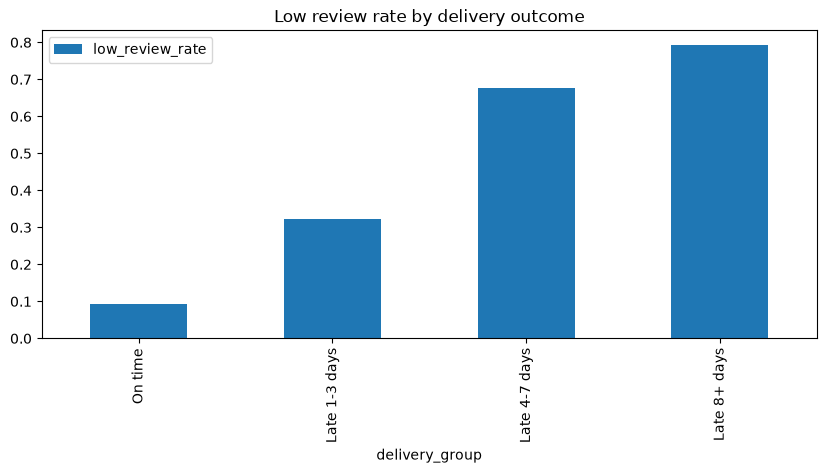

In [12]:
reviews = query("""
SELECT * FROM analysis.delivery_review_association
ORDER BY CASE delivery_group
    WHEN 'On time' THEN 1
    WHEN 'Late 1-3 days' THEN 2
    WHEN 'Late 4-7 days' THEN 3
    WHEN 'Late 8+ days' THEN 4
    ELSE 5
END
""")
display(reviews)
reviews.plot.bar(x='delivery_group', y='low_review_rate', figsize=(10,4), title='Low review rate by delivery outcome')
plt.show()